# Fouten, afweging en beperkte integratie

**Concept op verzoek van de gebruiker, uitgewerkt met Codex.** Milan moet
de keuzes en eigen bijdrage zelf beoordelen. Alle nieuwe bestanden blijven onder
`solutions/milan`. We gebruiken de cursusmethoden en de oorspronkelijke elf
invoervelden. Geen nieuwe onafhankelijke eindtest of menselijke review geclaimd.
De dure training is afzonderlijk werkelijk uitgevoerd; onderstaande rapportcellen
    worden van boven naar beneden uitgevoerd; de precieze uitvoeringsmethode staat
in de notebookmetadata en uitvoeringsreceipt.

## Alle procedures op dezelfde buitenfolds
Geen testset is opnieuw gebruikt om een winnaar te kiezen. Deze grafiek toont ontwikkelbewijs, met spreiding over folds en foutaantallen.

,model,macro_f1_mean,recall_p_mean,fn_total,fp_total
0,rf300_reference_default,0.761876,0.604390,614,256
1,rf_compatible_default,0.764623,0.617291,594,271
2,rf_compatible_f1_threshold,0.769125,0.668171,515,356
3,gradient_boosting_default,0.765045,0.612142,602,258
4,gradient_boosting_f1_threshold,0.761895,0.644388,552,338
5,rf_features_default,0.765882,0.620510,589,272
6,rf_features_f1_threshold,0.768609,0.645016,551,311
7,svm_default,0.703730,0.632115,571,572
8,svm_f1_threshold,0.700834,0.651434,541,625


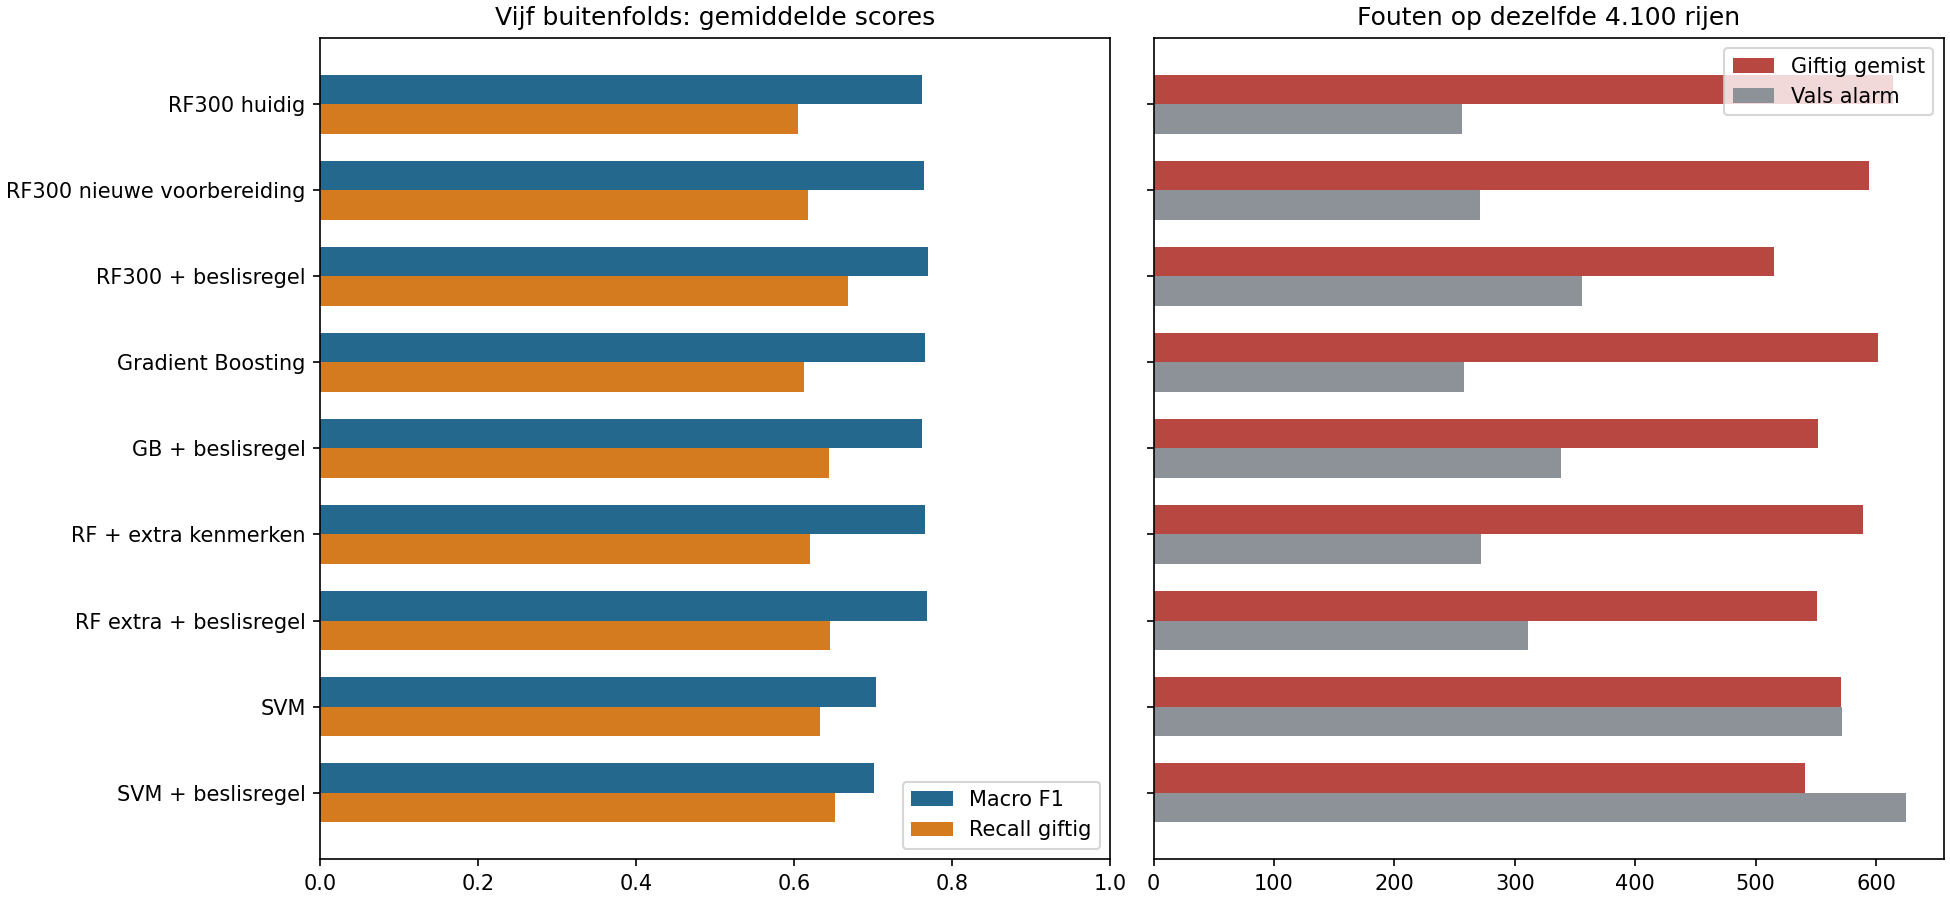

In [1]:
from pathlib import Path
import json, sys
import numpy as np
import pandas as pd
HERE = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'results_v2/summary.csv').exists())
sys.path.insert(0, str(HERE))
from mushroom_alternative import development_data, scores
from improve import experiments, make_pipeline, Measurements
X, y, ids, folds = development_data()
summary = pd.read_csv(HERE/'results_v2/summary.csv')
details = pd.read_csv(HERE/'results_v2/outer_fold_metrics.csv')
selections = json.loads((HERE/'results_v2/selections.json').read_text())
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import Image, display
display(summary[['model','macro_f1_mean','recall_p_mean','fn_total','fp_total']])
from build_v2_reports import LABELS
labels = summary.model.map(LABELS)
fig, axes = plt.subplots(1,2,figsize=(13,6),layout='constrained')
pos = np.arange(len(summary))
axes[0].barh(pos-.17,summary.macro_f1_mean,height=.34,label='Macro F1',color='#24688e')
axes[0].barh(pos+.17,summary.recall_p_mean,height=.34,label='Recall giftig',color='#d47b20')
axes[0].set(yticks=pos,yticklabels=labels,xlim=(0,1),title='Vijf buitenfolds: gemiddelde scores')
axes[0].legend();axes[0].invert_yaxis()
axes[1].barh(pos-.17,summary.fn_total,height=.34,label='Giftig gemist',color='#b74740')
axes[1].barh(pos+.17,summary.fp_total,height=.34,label='Vals alarm',color='#8d9198')
axes[1].set(yticks=pos,yticklabels=['']*len(pos),title='Fouten op dezelfde 4.100 rijen')
axes[1].legend();axes[1].invert_yaxis()
fig.savefig(HERE/'results_v2/vergelijking.png',dpi=150)
plt.close(fig)
display(Image(filename=str(HERE/'results_v2/vergelijking.png')))


## Waar blijft de kandidaat fouten maken?
De rijen hieronder zijn buitenfoldvoorspellingen, niet de finale fit op zichzelf. De groepering op ontbrekende waarden is achteraf diagnostisch en bewijst geen oorzaak.

In [2]:
pred = pd.read_csv(HERE/'results_v2/outer_oof_predictions.csv',float_precision='round_trip')
chosen = pred[pred.model=='rf_compatible_f1_threshold'].copy()
assert chosen.source_row.is_unique and set(chosen.source_row)==set(ids)
missing = pd.Series(X.isna().sum(axis=1).to_numpy(),index=ids)
chosen['missing_count'] = chosen.source_row.map(missing)
chosen['missing_group'] = pd.cut(chosen.missing_count,[-1,2,4,11],labels=['0-2','3-4','5+'])
chosen['FN'] = (chosen.true_class==1)&(chosen.prediction==0)
chosen['FP'] = (chosen.true_class==0)&(chosen.prediction==1)
errors = chosen.groupby('missing_group',observed=True).agg(rows=('source_row','size'),poisonous=('true_class','sum'),FN=('FN','sum'),FP=('FP','sum'))
errors['recall_p'] = 1-errors.FN/errors.poisonous
display(errors)
errors.to_csv(HERE/'results_v2/errors_by_missing.csv')
display(chosen[chosen.FN].sort_values('probability_p').head(10))


,rows,poisonous,FN,FP,recall_p
missing_group,,,,,
0-2,1221,480,117,84,0.756250
3-4,2326,876,310,218,0.646119
5+,553,196,88,54,0.551020


,source_row,fold,true_class,model,probability_p,threshold,prediction,missing_count,missing_group,FN,FP
8575,1781,3,1,rf_compatible_f1_threshold,0.021926,0.46,0,1,0-2,True,False
10051,642,4,1,rf_compatible_f1_threshold,0.022229,0.46,0,3,3-4,True,False
8743,3757,3,1,rf_compatible_f1_threshold,0.031835,0.46,0,4,3-4,True,False
8753,825,3,1,rf_compatible_f1_threshold,0.032747,0.46,0,2,0-2,True,False
8831,573,3,1,rf_compatible_f1_threshold,0.038108,0.46,0,5,5+,True,False
10068,3835,4,1,rf_compatible_f1_threshold,0.041864,0.46,0,3,3-4,True,False
10292,2860,4,1,rf_compatible_f1_threshold,0.046810,0.46,0,1,0-2,True,False
8615,3369,3,1,rf_compatible_f1_threshold,0.047155,0.46,0,2,0-2,True,False
12078,3764,5,1,rf_compatible_f1_threshold,0.047997,0.47,0,3,3-4,True,False
5570,3149,1,1,rf_compatible_f1_threshold,0.048203,0.46,0,2,0-2,True,False


## Ruwe classifier en beslispolicy niet verwarren
De bestaande modellezer blijft labels bij de oorspronkelijke grens geven. De preview kiest de waarschuwing met de apart vastgelegde drempel. De twee metrieksets worden apart opgeslagen; geen oude testcijfers bij een nieuw model.

In [3]:
package = json.loads((HERE/'results_v2/candidate_package.json').read_text())
manifest = json.loads((HERE/'artifacts/mushroom_rf300.json').read_text())
display(pd.Series(package))
print('Ruwe classificatiegrens:',manifest['raw_classifier_threshold'])
print('Voorgestelde beslisgrens:',manifest['proposed_decision_threshold'])
print('Raw metric scope:',manifest['metrics']['metrics_scope'])
print('Policy metric scope: buitenfolds, afzonderlijke beslispolicy')
assert package['labels_disagree']==0 and package['development_test_rows_scored']==0


Ruwe classificatiegrens: 0.5
Voorgestelde beslisgrens: 0.44999999999999996
Raw metric scope: outer CV on 4100 development rows
Policy metric scope: buitenfolds, afzonderlijke beslispolicy


acceptance                               {'family': 'rf_compatible', 'policy': 'f1_thre...
parameters                               {'classifier__class_weight': 'balanced', 'clas...
selection_cv_macro_f1_not_independent                                             0.767426
pipeline_sha256                          214f74bddab775da69069f87272e788ece18d8f5fef80b...
export_rows_checked                                                                   4100
proposed_decision_threshold                                                           0.45
original_runtime_raw_threshold                                                         0.5
export_max_probability_difference                                                      0.0
labels_disagree                                                                          0
input_features                           [cap_diameter, stem_height, stem_width, spore_...
custom_pickle_classes                                                                False

Lees [RESULTATEN_V2.md](RESULTATEN_V2.md) en [INTEGRATIE.md](INTEGRATIE.md). De notebookuitvoering is controleerbaar in `results_v2/notebook_execution.json`. Een later nieuw eindonderzoek vereist nieuwe evaluatiedata; opnieuw shuffelen lost de oude testbesmetting niet op.